In [3]:
import json
from pathlib import Path 

# Cargar metadatos 
metadata_path = Path("../src/models") / "metadata.json"
with open(metadata_path, "r", encoding="utf-8") as f:
    metadata = json.load(f)

print(json.dumps(metadata, indent=4, ensure_ascii=False))

IMG_SIZE = metadata["image_size"]
BATCH_SIZE = metadata["batch_size"]
CLASS_NAMES = metadata["class_names"]
NUM_CLASSES = len(CLASS_NAMES)
SEED = metadata["seed"]
MODELOS_DIR = metadata["MODELOS_DIR"]
RESULTS_DIR = metadata["RESULTS_DIR"]
EPOCHS  = metadata["EPOCHS"]
ruta_dataset = metadata["DATASET_DIR"]
ruta_train = ruta_dataset + "/train"
ruta_val = ruta_dataset + "/val"
ruta_test = ruta_dataset + "/test"

{
    "class_names": [
        "1. Enfeksiyonel",
        "2. Ekzama",
        "3. Akne",
        "4. Pigment",
        "5. Benign",
        "6. Malign"
    ],
    "image_size": [
        224,
        224
    ],
    "batch_size": 16,
    "label_mode": "int",
    "seed": 42,
    "tensorflow_version": "2.10.0",
    "EPOCHS": 10,
    "SEED": 42,
    "MODELOS_DIR": "../src/models",
    "RESULTS_DIR": "../src/models/resultados",
    "DATASET_DIR": "../data/processed/"
}


In [4]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    recall_score,
)
from sklearn.utils.class_weight import compute_class_weight

keras.utils.set_random_seed(SEED)

# Puede reducir la velocidad; facilita reproducir el experimento.
tf.config.experimental.enable_op_determinism()

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.10.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [ ]:

NUM_CLASSES = len(CLASS_NAMES)
CLASS_IDS = np.arange(NUM_CLASSES)
MALIGN_IDX = CLASS_NAMES.index("6. Malign")

# Usa la misma resolución que en tu baseline.
IMG_SIZE = (IMG_SIZE[0], IMG_SIZE[1])  # (224, 224)
BATCH_SIZE = BATCH_SIZE

USE_AUGMENTATION = False    
USE_CLASS_WEIGHTS = False

HEAD_EPOCHS = 5
FINE_TUNE_EPOCHS = EPOCHS - HEAD_EPOCHS
HEAD_LR = 1e-3
FINE_TUNE_LR = 1e-5

BEST_MODEL_PATH = Path(MODELOS_DIR) / "mobilenetv2.keras"

assert Path(ruta_train).is_dir(), f"No existe {ruta_train}"
assert Path(ruta_val).is_dir(), f"No existe {ruta_val}"

**Cargar las particiones:** Fijamos el orden de las clases y desactivamos el barajado en validación para mantener alineadas las etiquetas y predicciones. image_dataset_from_directory permite establecer ambos parámetros.

In [9]:
def load_partition(directory, shuffle):
    return keras.utils.image_dataset_from_directory(
        directory,
        labels="inferred",
        label_mode="int",
        class_names=CLASS_NAMES,
        color_mode="rgb",
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED,
    )

train_raw = load_partition(ruta_train, shuffle=True)
val_raw = load_partition(ruta_val, shuffle=False)

train_paths = list(train_raw.file_paths)
val_paths = list(val_raw.file_paths)

# Las etiquetas de entrenamiento se usan solamente para contar clases.
y_train = np.concatenate([
    labels.numpy() for _, labels in train_raw
])
y_val = np.concatenate([
    labels.numpy() for _, labels in val_raw
])

distribution = pd.DataFrame({
    "clase": CLASS_NAMES,
    "train": np.bincount(y_train, minlength=NUM_CLASSES),
    "val": np.bincount(y_val, minlength=NUM_CLASSES),
})
display(distribution)

# Comprueba el soporte del informe original.
expected_val_support = np.array([159, 74, 175, 111, 1014, 823])
actual_val_support = np.bincount(y_val, minlength=NUM_CLASSES)

assert np.array_equal(actual_val_support, expected_val_support), (
    "La distribución de validación no coincide con el baseline. "
    "Revisa la partición y el orden de clases."
)

# Esta comprobación no garantiza que sean las mismas imágenes:
# para eso debes reutilizar la partición original.
pd.DataFrame({
    "path": val_paths,
    "label": y_val,
}).to_csv(Path(RESULTS_DIR) / "validation_manifest.csv", index=False)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_raw.prefetch(AUTOTUNE)
val_ds = val_raw.prefetch(AUTOTUNE)

Found 25918 files belonging to 6 classes.
Found 2356 files belonging to 6 classes.


,clase,train,val
0,1. Enfeksiyonel,3830,159
1,2. Ekzama,2539,74
2,3. Akne,2063,175
3,4. Pigment,995,111
4,5. Benign,9770,1014
5,6. Malign,6721,823


Calculamos los pesos de las clases. (No se usan porque en la comparación del baseline con el primer experimento Macro F1 del dataset validacion di mejor resultado sin DataAugmentation ni ClassWeigths)

In [10]:
assert np.all(np.bincount(y_train, minlength=NUM_CLASSES) > 0), (
    "Faltan clases en entrenamiento."
)

if USE_CLASS_WEIGHTS:
    weights = compute_class_weight(
        class_weight="balanced",
        classes=CLASS_IDS,
        y=y_train,
    )
    class_weights = {
        int(class_id): float(weight)
        for class_id, weight in zip(CLASS_IDS, weights)
    }
else:
    class_weights = None

print("Class weights:", class_weights)

Class weights: None


Compilamos el modelo. Lo hacemos sin Data Augmentation, pero está preparado para hacerlo poniendo USE_AUGMENTATION a True

In [11]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05, fill_mode="reflect"),
    layers.RandomZoom(0.10, fill_mode="reflect"),
], name="augmentation")

base_model = keras.applications.MobileNetV2(
    input_shape=(*IMG_SIZE, 3),
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3), name="image")
x = augmentation(inputs) if USE_AUGMENTATION else inputs
x = layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1.0,
    name="mobilenet_preprocessing",
)(x)

# Mantiene BatchNormalization en modo inferencia.
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="class_probabilities",
)(x)

model = keras.Model(inputs, outputs, name="MobileNetV2_skin")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=HEAD_LR),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

model.summary()

9406464/9406464 [==============================] - 1s 0us/step
Model: "MobileNetV2_skin"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 image (InputLayer)          [(None, 224, 224, 3)]     0         
                                                                 
 mobilenet_preprocessing (Re  (None, 224, 224, 3)      0         
 scaling)                                                        
                                                                 
 mobilenetv2_1.00_224 (Funct  (None, 7, 7, 1280)       2257984   
 ional)                                                          
                                                                 
 global_average_pooling2d (G  (None, 1280)             0         
 lobalAveragePooling2D)                                          
                                                                 
 dropout (Dropout)           (None, 1280)            

Seleccionamos el mejor checkponit por macro F1

In [ ]:
class ValidationMacroF1(keras.callbacks.Callback):
    def __init__(self, dataset, y_true, save_path):
        super().__init__()
        self.dataset = dataset
        self.y_true = np.asarray(y_true)
        self.save_path = str(save_path)
        self.best = -np.inf
        self.records = []

    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}

        probabilities = self.model.predict(self.dataset, verbose=0)
        predictions = probabilities.argmax(axis=1)

        macro_f1 = f1_score(
            self.y_true,
            predictions,
            labels=CLASS_IDS,
            average="macro",
            zero_division=0,
        )

        logs["val_macro_f1"] = float(macro_f1)
        self.records.append({
            "validation_check": len(self.records) + 1,
            "val_macro_f1": float(macro_f1),
        })

        print(f" — val_macro_f1: {macro_f1:.4f}")

        if macro_f1 > self.best:
            self.best = float(macro_f1)
            self.model.save(self.save_path)
            print(f"   Mejor checkpoint guardado: {macro_f1:.4f}")


macro_callback = ValidationMacroF1(
    dataset=val_ds,
    y_true=y_val,
    save_path=BEST_MODEL_PATH,
)

print(f"Modelo guardado en: {BEST_MODEL_PATH}")
print(f"Tamaño: {BEST_MODEL_PATH.stat().st_size / (1024**2):.2f} MB")

def make_callbacks():
    # macro_callback debe ir antes de los callbacks que leen val_macro_f1.
    return [
        macro_callback,
        keras.callbacks.EarlyStopping(
            monitor="val_macro_f1",
            mode="max",
            patience=5,
            restore_best_weights=True,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_macro_f1",
            mode="max",
            factor=0.5,
            patience=2,
            min_lr=1e-7,
        ),
        keras.callbacks.TerminateOnNaN(),
    ]

Entrenamos la cabeza

In [13]:
history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=HEAD_EPOCHS,
    class_weight=class_weights,
    callbacks=make_callbacks(),
)

Epoch 1/5
1619/1620 [============================>.] - ETA: 0s - loss: 0.9905 - accuracy: 0.6060 — val_macro_f1: 0.6145
   Mejor checkpoint guardado: 0.6145
1620/1620 [==============================] - 83s 50ms/step - loss: 0.9905 - accuracy: 0.6060 - val_loss: 0.7144 - val_accuracy: 0.7211 - val_macro_f1: 0.6145 - lr: 0.0010
Epoch 2/5
1619/1620 [============================>.] - ETA: 0s - loss: 0.8737 - accuracy: 0.6531 — val_macro_f1: 0.6383
   Mejor checkpoint guardado: 0.6383
1620/1620 [==============================] - 82s 50ms/step - loss: 0.8737 - accuracy: 0.6530 - val_loss: 0.6970 - val_accuracy: 0.7284 - val_macro_f1: 0.6383 - lr: 0.0010
Epoch 3/5
1620/1620 [==============================] - ETA: 0s - loss: 0.8548 - accuracy: 0.6590 — val_macro_f1: 0.6450
   Mejor checkpoint guardado: 0.6450
1620/1620 [==============================] - 85s 52ms/step - loss: 0.8548 - accuracy: 0.6590 - val_loss: 0.7088 - val_accuracy: 0.7407 - val_macro_f1: 0.6450 - lr: 0.0010
Epoch 4/5
1620/1

Fine-tuning

In [14]:
model = keras.models.load_model(BEST_MODEL_PATH)

base_model = next(
    layer for layer in model.layers
    if isinstance(layer, keras.Model)
    and "mobilenet" in layer.name.lower()
)

base_model.trainable = True

# Entrenar solo las últimas 30 capas, excepto BatchNormalization.
for layer in base_model.layers:
    layer.trainable = False

for layer in base_model.layers[-30:]:
    if not isinstance(layer, layers.BatchNormalization):
        layer.trainable = True

# Es necesario recompilar tras cambiar qué capas son entrenables.
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=FINE_TUNE_LR),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    class_weight=class_weights,
    callbacks=make_callbacks(),
)

print("Mejor macro F1 de ambas fases:", macro_callback.best)

Epoch 1/5
1620/1620 [==============================] - 106s 64ms/step - loss: 0.7411 - accuracy: 0.7007 - val_loss: 0.6245 - val_accuracy: 0.7500 - val_macro_f1: 0.6388 - lr: 1.0000e-05
Epoch 2/5
1619/1620 [============================>.] - ETA: 0s - loss: 0.6445 - accuracy: 0.7419 — val_macro_f1: 0.6773
   Mejor checkpoint guardado: 0.6773
1620/1620 [==============================] - 106s 65ms/step - loss: 0.6445 - accuracy: 0.7418 - val_loss: 0.5624 - val_accuracy: 0.7852 - val_macro_f1: 0.6773 - lr: 1.0000e-05
Epoch 3/5
1620/1620 [==============================] - ETA: 0s - loss: 0.5772 - accuracy: 0.7732 — val_macro_f1: 0.6859
   Mejor checkpoint guardado: 0.6859
1620/1620 [==============================] - 107s 66ms/step - loss: 0.5772 - accuracy: 0.7732 - val_loss: 0.5427 - val_accuracy: 0.7895 - val_macro_f1: 0.6859 - lr: 1.0000e-05
Epoch 4/5
1620/1620 [==============================] - ETA: 0s - loss: 0.5191 - accuracy: 0.7970 — val_macro_f1: 0.7023
   Mejor checkpoint guardado

Evaluar mejor modelo

In [16]:
best_model = keras.models.load_model(BEST_MODEL_PATH)

probabilities = best_model.predict(val_ds, verbose=1)
y_pred = probabilities.argmax(axis=1)

print(classification_report(
    y_val,
    y_pred,
    labels=CLASS_IDS,
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0,
))

recall_per_class = recall_score(
    y_val,
    y_pred,
    labels=CLASS_IDS,
    average=None,
    zero_division=0,
)

new_metrics = {
    "accuracy": float(accuracy_score(y_val, y_pred)),
    "macro_f1": float(f1_score(
        y_val, y_pred,
        labels=CLASS_IDS,
        average="macro",
        zero_division=0,
    )),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_val, y_pred)
    ),
    "recall_malign": float(recall_per_class[MALIGN_IDX]),
}

for name, value in new_metrics.items():
    print(f"{name}: {value:.6f}")

report = classification_report(
    y_val,
    y_pred,
    labels=CLASS_IDS,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

pd.DataFrame(report).T.to_csv(
    Path(RESULTS_DIR) / "classification_report.csv"
)

prediction_table = pd.DataFrame({
    "path": val_paths,
    "y_true": y_val,
    "y_pred": y_pred,
})
for idx, class_name in enumerate(CLASS_NAMES):
    prediction_table[f"prob_{class_name}"] = probabilities[:, idx]

prediction_table.to_csv(
    Path(RESULTS_DIR) / "validation_predictions.csv",
    index=False,
)

with open(Path(RESULTS_DIR) / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(new_metrics, f, indent=2, ensure_ascii=False)

148/148 [==============================] - 7s 42ms/step
                 precision    recall  f1-score   support

1. Enfeksiyonel     0.4485    0.7673    0.5661       159
      2. Ekzama     0.4459    0.4459    0.4459        74
        3. Akne     0.8727    0.8229    0.8471       175
     4. Pigment     0.9333    0.5045    0.6550       111
      5. Benign     0.8718    0.8984    0.8849      1014
      6. Malign     0.8635    0.7764    0.8177       823

       accuracy                         0.8086      2356
      macro avg     0.7393    0.7026    0.7028      2356
   weighted avg     0.8299    0.8086    0.8125      2356

accuracy: 0.808574
macro_f1: 0.702776
balanced_accuracy: 0.702575
recall_malign: 0.776428


In [ ]:

# Nombre del modelo experimental
MODEL_PATH = Path(MODELOS_DIR) / "exp02_mobilenetv2.keras"

# Guardar el modelo completo
model.save(MODEL_PATH)

print(f"Modelo guardado en: {MODEL_PATH}")
print(f"Tamaño: {MODEL_PATH.stat().st_size / (1024**2):.2f} MB")

**Matrices de confusión.**
La segunda matriz permite ver el porcentaje de aciertos y errores dentro de cada clase, sin que el tamaño de Benign o Malign eclipse las demás.


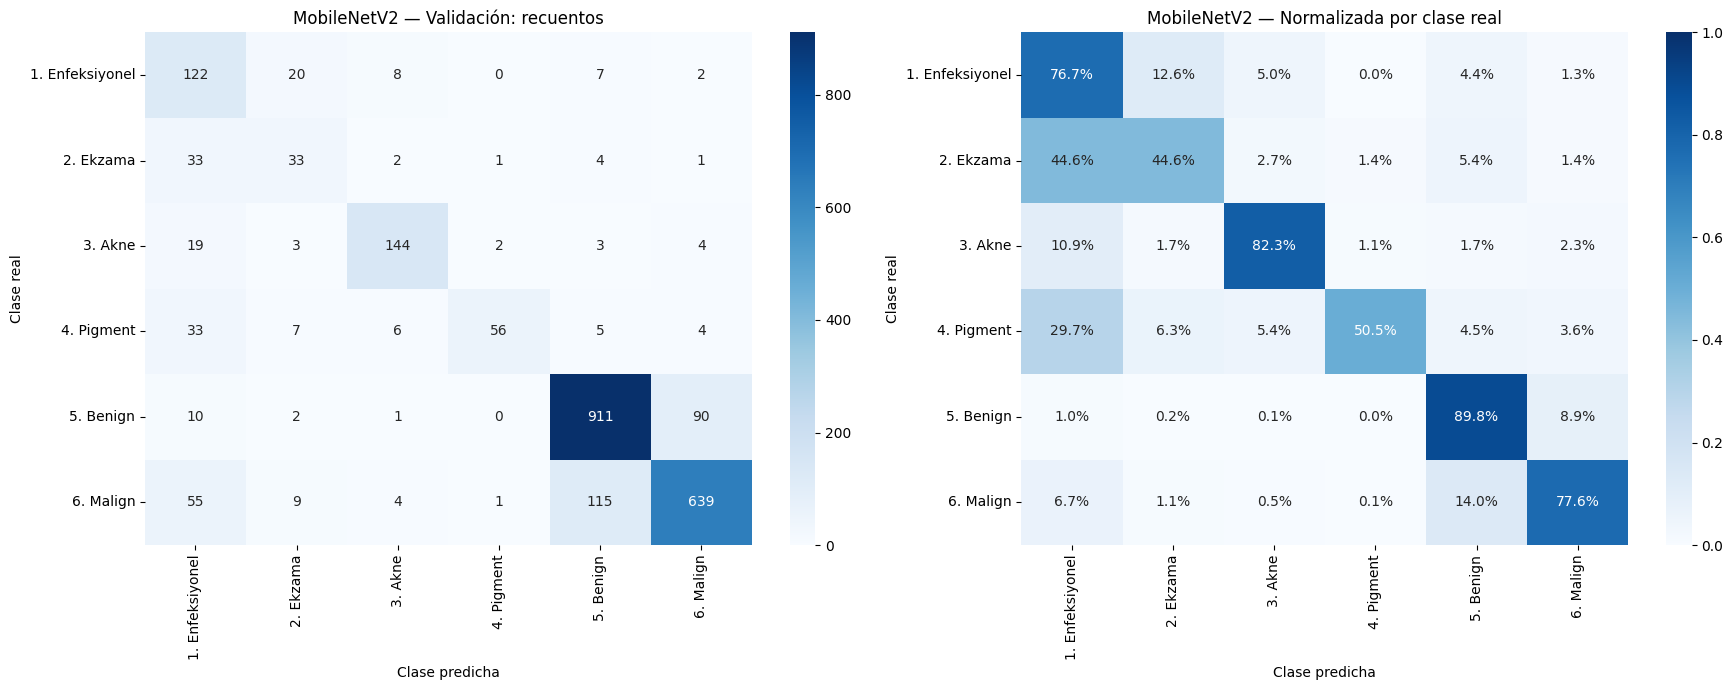

In [18]:
cm = confusion_matrix(y_val, y_pred, labels=CLASS_IDS)
cm_normalized = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[0],
)
axes[0].set_title("MobileNetV2 — Validación: recuentos")

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".1%",
    cmap="Blues",
    vmin=0,
    vmax=1,
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[1],
)
axes[1].set_title("MobileNetV2 — Normalizada por clase real")

for ax in axes:
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.tick_params(axis="x", rotation=90)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.savefig(Path(RESULTS_DIR) / "confusion_matrices.png", dpi=160)
plt.show()

Actualizamos el fichero de resultados anteriores con los de este modelo para poder comparar con otros experimentos.

In [22]:
from sklearn.metrics import precision_score, recall_score

# Ajusta esta ruta respecto al directorio de ejecución del notebook.
PREVIOUS_RESULTS_PATH = Path(RESULTS_DIR) / "comparativa_modelos.csv"

# Leemos resultados anteriores.
if not PREVIOUS_RESULTS_PATH.is_file():
    raise FileNotFoundError(
        f"No se encuentra el CSV: {PREVIOUS_RESULTS_PATH.resolve()}"
    )

previous_results = pd.read_csv(PREVIOUS_RESULTS_PATH)

metric_columns = [
    "accuracy",
    "macro_f1",
    "balanced_accuracy",
    "recall_malign",
    "precision_malign",
]

required_columns = ["modelo", "archivo"] + metric_columns

missing_columns = set(required_columns) - set(previous_results.columns)
if missing_columns:
    raise ValueError(
        f"Faltan columnas en el CSV: {sorted(missing_columns)}"
    )

# Completamos las métricas de MobileNetV2.
# Se calculan todas las clases para que la posición de Malign sea explícita.
class_ids = np.arange(len(CLASS_NAMES))
malign_idx = CLASS_NAMES.index("6. Malign")

precision_per_class = precision_score(
    y_val,
    y_pred,
    labels=class_ids,
    average=None,
    zero_division=0,
)

recall_per_class = recall_score(
    y_val,
    y_pred,
    labels=class_ids,
    average=None,
    zero_division=0,
)

mobilenet_results = pd.DataFrame([{
    "modelo": "MobileNetV2",
    "archivo": str(BEST_MODEL_PATH),
    "accuracy": float(new_metrics["accuracy"]),
    "macro_f1": float(new_metrics["macro_f1"]),
    "balanced_accuracy": float(new_metrics["balanced_accuracy"]),
    "recall_malign": float(recall_per_class[malign_idx]),
    "precision_malign": float(precision_per_class[malign_idx]),
}])

mobilenet_results.to_csv(
    f"{PREVIOUS_RESULTS_PATH}",
    mode="a",
    header=False,
    index=False
)

# 3. Guardar también MobileNetV2 por separado.
# Este archivo permitirá comparar desde otro notebook.
mobilenet_csv = Path(RESULTS_DIR) / "mobilenetv2_metricas_val.csv"
mobilenet_csv.parent.mkdir(parents=True, exist_ok=True)

mobilenet_results.to_csv(mobilenet_csv, index=False)